# Phase 4h: the Fang et al. (2025) test

**Status:** done 2026-11-04; method set completed 2026-11-07 (prompt 08, Part C below). Drivers: `code/R/04h_fang_test.R`, `code/R/04h3_fang_finalize.R`. Results: `results/2026-11-04/fang/`, `results/2026-11-07/fang/`.

**What Fang did:** Fang, Lee & Li (2025) regress renewable energy consumption on AI job postings, policy uncertainty and controls, all in logs, with state fixed effects, for 50 states + DC in 2018-2021 (N = 204). Their AI coefficient runs from 0.0396 to 0.0561 (Table 2, PDF p. 5).

**The replication story (rebuilt SEDS basis):** in Oct 2023 EIA changed how SEDS counts wind, solar, hydro and geothermal electricity (https://www.eia.gov/state/seds/seds-change/index.php). On current SEDS, Fang's column 6 is -0.0188 (p = 0.317). Rebuilding the old fossil-fuel-equivalence basis year by year from EIA's heat rates turns the sign positive but leaves it small: +0.0137 (p = 0.500) in column 6 and +0.0269 (p = 0.077) in column 2. **SEDS as published in June 2023 (the archived release, data through 2021), now the main old-basis series, largely reproduces Fang:** the same sign, a similar size in columns 1-2 (+0.0346 and +0.0435 against +0.0428 and +0.0452), and about two-thirds of Fang's size in column 6 (+0.0348, p = 0.057, against +0.0531). For column 6 with postings, 61% of the move from current to June 2023 SEDS comes from the accounting change and 39% from EIA's later data revisions (`results/2026-11-07/extend/tables/p2_gap_decomposition.csv`). The single-k version (k = 2.6) is kept only as a check. Fang's spec has no year effects: on the June 2023 basis, a linear trend turns column 6 to -0.0419 (p = 0.121), and pet-care employment is associated with renewables more strongly than AI. In our spec (two-way FE, lag, clustered, no DC), no basis gives a significant positive association.

**How this differs from the Zhang test (4b-4e):** different outcome (all renewable energy use, not the electricity share), different AI measure (job postings, not data-center jobs), different controls, no year effects and no lag. The Zhang test stays as it is.

In [1]:
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 70); pd.set_option('display.max_rows', 100)
L = '../logs/2026-11-04/'
post = pd.read_csv('../data/ai_job_postings_state.csv')
print('Postings:', post.shape, '| Fang panel:', pd.read_csv('../data/fang_panel.csv').shape)

Postings: (408, 13) | Fang panel: (561, 41)


## Coverage

Number of areas with data, out of 51, by variable and year.

In [2]:
display(pd.read_csv(L + 'fang_coverage.csv'))

,variable,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,first,last
0,re_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
1,wind_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
2,solar_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
3,geothermal_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
4,hydro_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
5,biomass_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
6,total_energy_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
7,ep_tetcd,51,51,51,51,51,51,51,51,51,51,0,2015,2024
8,edu_bach_per1000,51,51,51,51,51,51,51,51,51,51,0,2015,2024
9,gdp_real_musd2017,51,51,51,51,51,51,51,51,51,51,51,2015,2025


## AI job postings: where each year comes from

In [3]:
t = post.groupby(['year', 'edition', 'vendor', 'vintage', 'figure'], dropna=False).agg(sum_of_51=('postings', 'sum'), page=('page', 'first')).reset_index()
t['national_change_pct'] = t.sum_of_51.pct_change().mul(100).round(0)
display(t)

,year,edition,vendor,vintage,figure,sum_of_51,page,national_change_pct
0,2018,2019,Burning Glass,ed2019_bg,Fig. 4.1.8 shows a scatter; values from its linked sheet,189030.0,82.0,NaN
1,2019,2022,Emsi Burning Glass,ed2022_ebg,"Public-data sheet, tab AI Job Postings by State; not printed in th...",325702.0,NaN,72.0
2,2020,2022,Emsi Burning Glass,ed2022_ebg,"Public-data sheet, tab AI Job Postings by State; not printed in th...",296937.0,NaN,-9.0
3,2021,2022,Emsi Burning Glass,ed2022_ebg,Fig. 4.1.6,404074.0,9.0,36.0
4,2022,2023,Lightcast,ed2023_lc,Fig. 4.1.6; share Fig. 4.1.8 (p. 11),795624.0,10.0,97.0
5,2023,2024,Lightcast,ed2024_lc,Fig. 4.2.7; share Fig. 4.2.9 (p. 18),461225.0,17.0,-42.0
6,2024,2025,Lightcast,ed2025_lc,Fig. 4.2.8; share Fig. 4.2.10 (p. 17),658548.0,16.0,43.0
7,2025,2026,Lightcast,ed2026_lc,Fig. 4.4.10; share Fig. 4.4.11 (p. 40),994372.0,40.0,51.0


## How to read the postings series

**In the postings extension (2019-2024), almost every year comes from a different edition. So a state's year-to-year change mixes real change with method changes.** Year effects remove shifts that hit all states proportionally. The share-of-national row can't test this: once year effects are in, it equals the postings row by construction (-0.0475 vs -0.0479). Anything uneven stays in as noise, and the edition overlap and share-change tables are the evidence on that. Data-center jobs (BLS, one consistent series) remain the more reliable extension measure.

National totals swing +97% in 2022 and -42% in 2023 around reported method changes. Those are the shifts year effects can absorb, but only if they hit states proportionally.

## Checks on the postings table

In [4]:
display(pd.read_csv(L + 'ai_postings_checks.csv'))

,year,check,result,detail
0,2018,51 rows,ok,"sum of 51 = 189,030; yoy"
1,2019,51 rows,ok,"sum of 51 = 325,702; yoy +72%"
2,2020,51 rows,ok,"sum of 51 = 296,937; yoy -9%"
3,2021,51 rows,ok,"sum of 51 = 404,074; yoy +36%"
4,2022,51 rows,ok,"sum of 51 = 795,624; yoy +97%"
5,2023,51 rows,ok,"sum of 51 = 461,225; yoy -42%"
6,2024,51 rows,ok,"sum of 51 = 658,548; yoy +43%"
7,2025,51 rows,ok,"sum of 51 = 994,372; yoy +51%"
8,2022,sum vs national total implied by published shares,ok,"implied 795,471; sum 795,624; gap -0.02%; max |published - derived..."
9,2023,sum vs national total implied by published shares,ok,"implied 461,332; sum 461,225; gap +0.02%; max |published - derived..."


## Edition overlap

Levels can't be compared when one edition covers Jan-Sep and the other the full year, but each state's **share of U.S. AI postings** can. These are the only years two editions report for all states.

**Reading it:** the state pattern is very similar across editions, but high correlations are driven by the ordering of large and small states, so they don't clear within-state noise. For 2019 the median state's share still differs by 14.8% (SD of the log ratio 0.162), part of which is Jan-Sep against the full year. For 2020, with both full years, the median gap is 0.7%, so a one-year revision within Burning Glass is small.

In [5]:
display(pd.read_csv(L + 'ai_postings_overlap.csv').drop(columns=['comparison']))

,year,edition_a,edition_b,n_states,pearson_share,spearman_share,pearson_ln_share,level_ratio_b_over_a,sd_ln_share_ratio,median_abs_pct_gap,largest_gaps
0,2019,"2019 edition, Jan-Sep","2022 edition, full year",51,0.9978,0.9954,0.9969,2.0000,0.1616,14.7934,MT -45%; AK -45%; MS -41%
1,2020,2021 edition,2022 edition,51,1.0000,0.9996,1.0000,0.9883,0.0116,0.6547,WV +4%; OR +3%; VT +3%
2,2021,"2022 edition, PDF map","2022 edition, sheet",51,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,AK +0%; PA +0%; ND +0%


### Four states, across editions

The 2023-2026 editions print a share history for CA, NY, TX and WA, and it's the same in all four. For 2022 onward it matches our table. For 2018-2021 it's Lightcast's restated history, which differs from the Burning Glass tables we use. **WA's fall from 4.8% to 3.9% at 2021-2022 in our table doesn't exist in Lightcast's own series (3.94 to 3.93): it's a method change.**

In [6]:
display(pd.read_csv(L + 'ai_postings_select_states.csv'))

,state,year,series_2023,series_2024,series_2025,series_2026,table_share_pct,table_edition,alt_share_pct
0,CA,2018,22.522,22.52,22.52,22.522,25.959,2019,NaN
1,CA,2019,24.619,24.62,24.62,24.619,24.512,2022,27.458
2,CA,2020,20.877,20.88,20.88,20.877,21.055,2022,21.113
3,CA,2021,19.507,19.51,19.51,19.507,19.857,2022,NaN
4,CA,2022,17.867,17.87,17.87,17.867,17.870,2023,NaN
5,CA,2023,NaN,15.31,15.31,15.314,15.310,2024,NaN
6,CA,2024,NaN,NaN,15.70,15.697,15.700,2025,NaN
7,CA,2025,NaN,NaN,NaN,17.185,17.180,2026,NaN
8,NY,2018,7.037,7.04,7.04,7.037,8.221,2019,NaN
9,NY,2019,7.686,7.69,7.69,7.686,7.573,2022,8.811


### How much state shares move each year

SD across states of the year-to-year change in ln(state share). Postings shares move 1.3 to 3.2 times as much as data-center jobs in every step, including the two same-edition steps. Steps across editions are somewhat larger on average (0.227 against 0.195). So postings are noisy at the state level for more reasons than edition changes.

In [7]:
display(pd.read_csv(L + 'ai_postings_share_changes.csv'))

,step,editions,same_edition,national_change_pct,sd_ln_share_change_postings,median_abs_ln_share_change,sd_ln_share_change_dc_jobs,n_dc_jobs,largest
0,2018->2019,2019->2022,False,72.3018,0.2230,0.1395,0.1196,51,MS +90%; IN +81%; AK +81%
1,2019->2020,2022->2022,True,-8.8317,0.1738,0.1155,0.1294,51,HI +111%; ID +63%; ND +33%
2,2020->2021,2022->2022,True,36.0807,0.2166,0.1761,0.0957,51,AR +95%; WY +82%; ID +70%
3,2021->2022,2022->2023,False,96.9006,0.2663,0.1313,0.1045,51,AR +139%; OK +99%; KS +90%
4,2022->2023,2023->2024,False,-42.0298,0.2493,0.1400,0.0829,51,AK +133%; MT +85%; ND +82%
5,2023->2024,2024->2025,False,42.7824,0.2004,0.1217,0.0618,51,MT +93%; WV +70%; MD -36%
6,2024->2025,2025->2026,False,50.9946,0.1951,0.0905,0.0775,47,VT +126%; WY +78%; WV +69%


# Part B: models

All results are associations. **Data-center jobs (BLS, one consistent series) are the more reliable extension measure.** Postings are Fang's measure, and they're stitched from different report editions.

In [8]:
T = '../results/2026-11-04/fang/tables/'
print('Gate:', pd.read_csv('../results/2026-11-04/fang/gate.csv').ok.all())

Gate: True


## 1. Replication: what Fang did, and what we get

**What we did:** Fang's equation 2 on 2018-2021 with DC, state fixed effects only, adding controls one at a time (their Table 2).

**What we find: it doesn't reproduce on current data.** Column 6 is -0.0188 (p = 0.317) against Fang's +0.0531.

**Why, as far as we can tell:** in October 2023, starting with the 2022 data cycle, EIA changed how SEDS counts wind, solar, hydro and geothermal, for all years ([EIA notice](https://www.eia.gov/state/seds/seds-change/index.php)). Before, it counted them at about the fuel a fossil plant would have burned. Now it counts the electricity's own energy content. Fang's paper names no SEDS release and was received in December 2024, but it says EIA's renewable data ended in 2021 (PDF p. 3), and its Table 2 constants imply a mean log outcome of about 11.79, which fits the old way and not the current one (11.44). Biomass doesn't change, so "total renewables" today is mostly biomass (59-68% of the U.S. total in 2018-2024).

**The check:** we rebuilt the total on approximately the old basis: biomass + k x the other four, with k = 2.3, 2.6 and 2.9. It's approximate, because one k stands in for each year's heat rate: **k = 2.3-2.9 is our approximation of the old accounting**, not EIA's. **The positive sign comes back:** column 2 is +0.0342 (p = 0.025) at k = 2.6, against Fang's +0.0452. Column 6 is +0.0216 (p = 0.287), positive but about 40% of Fang's and not significant.

**Vintage of postings isn't the cause:** using each year as first published gives -0.0414 (p = 0.014) in column 6.

In [9]:
display(pd.read_csv(T + 'replication.csv'))

,Version,"Measure, sample",N,(1) AI,(2) + EPU,(3) + EP,(4) + GDP,(5) + POP,(6) + EDU
0,Fang Table 2 (published),"AI postings, 2018-2021",204,0.0428*** (0.015),0.0452*** (0.015),0.0396** (0.015),0.0548*** (0.016),0.0561*** (0.019),0.0531*** (0.019)
1,Current SEDS,"AI postings, 2018-2021",204,-0.0288** (0.0141),-0.0100 (0.0139),-0.0189 (0.0159),-0.0159 (0.0183),-0.0183 (0.0186),-0.0188 (0.0187)
2,"Current SEDS, same vintage","AI postings, 2019-2021",153,0.0023 (0.0266),-0.0240 (0.0246),-0.0762* (0.0400),-0.0680* (0.0401),-0.0851* (0.0435),-0.0852* (0.0437)
3,"Current SEDS, as first published","AI postings, 2018-2021",204,-0.0355*** (0.0107),-0.0152 (0.0116),-0.0357** (0.0152),-0.0345** (0.0158),-0.0412** (0.0166),-0.0414** (0.0166)
4,"Approx. old SEDS, k = 2.3","AI postings, 2018-2021",204,0.0180 (0.0144),0.0284* (0.0149),0.0166 (0.0169),0.0188 (0.0195),0.0162 (0.0198),0.0165 (0.0199)
5,"Approx. old SEDS, k = 2.6","AI postings, 2018-2021",204,0.0251* (0.0145),0.0342** (0.0151),0.0219 (0.0171),0.0237 (0.0198),0.0213 (0.0201),0.0216 (0.0202)
6,"Approx. old SEDS, k = 2.9","AI postings, 2018-2021",204,0.0313** (0.0147),0.0393** (0.0153),0.0265 (0.0174),0.0281 (0.0201),0.0257 (0.0204),0.0262 (0.0205)
7,Current SEDS,"Data-center jobs, 2018-2021",204,-0.0950* (0.0508),-0.0503 (0.0487),-0.0735 (0.0526),-0.0674 (0.0536),-0.0651 (0.0541),-0.0655 (0.0542)
8,"Approx. old SEDS, k = 2.6","Data-center jobs, 2018-2021",204,0.0144 (0.0528),0.0299 (0.0537),-0.0216 (0.0572),-0.0272 (0.0583),-0.0220 (0.0587),-0.0218 (0.0589)


## 2. Bridge: which step changes the answer

Each row makes one change. Current SEDS.

- **Adding year effects** matters most for postings: -0.0188 becomes -0.1095 (p = 0.004). Fang's spec has no year effects, so it attributes national trends in renewables and postings to AI.
- **With the lag, clustering and longer sample,** neither measure is significant: postings -0.0479 (p = 0.109), data-center jobs -0.0567 (p = 0.208).
- **The share row equals the postings row** once year effects are in. That's algebra, not a test: ln(share) differs from ln(postings) only by the national total, which year effects absorb.

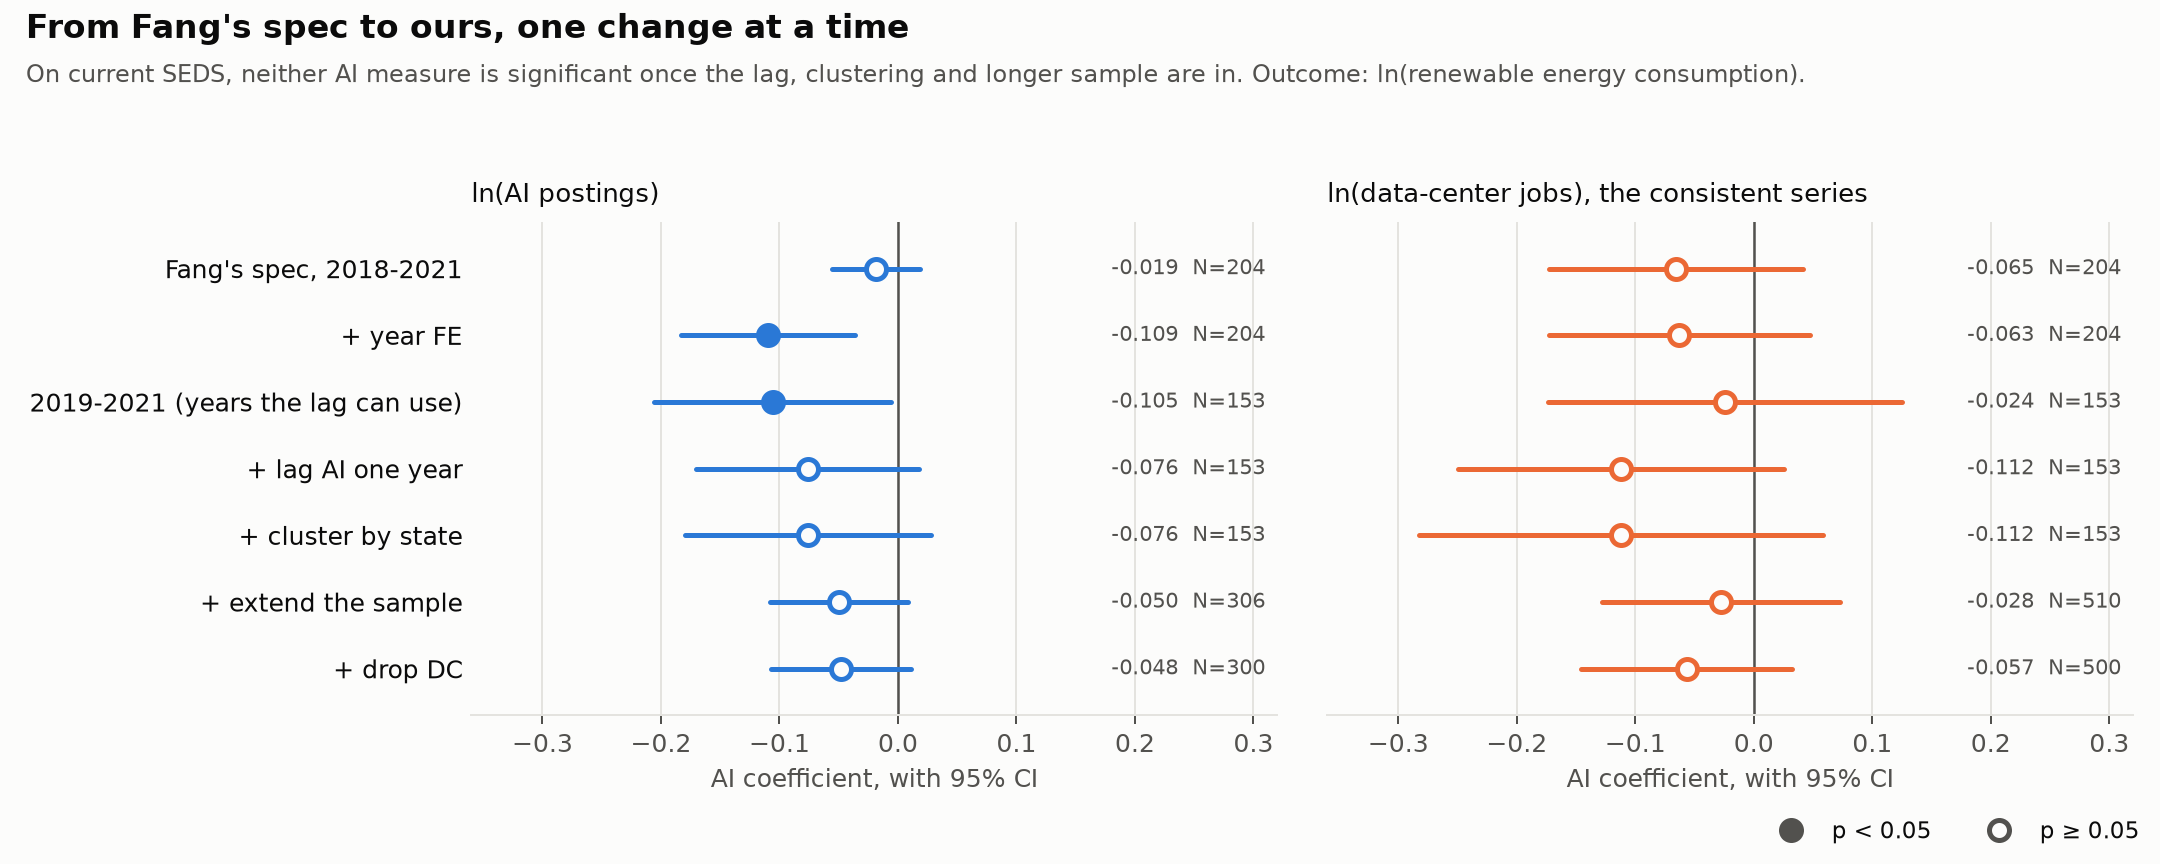

,Step,ln(AI postings),ln(share of national postings),ln(data-center jobs),"ln(jobs per 1,000)"
0,"Fang's spec, 2018-2021",-0.0188 (0.0187) [204],-0.0881*** (0.0334) [204],-0.0655 (0.0542) [204],-0.0743 (0.0528) [204]
1,+ year FE,-0.1095*** (0.0371) [204],-0.1094*** (0.0371) [204],-0.0628 (0.0558) [204],-0.0716 (0.0558) [204]
2,2019-2021 (years the lag can use),-0.1055** (0.0503) [153],-0.1054** (0.0503) [153],-0.0242 (0.0754) [153],-0.0360 (0.0754) [153]
3,+ lag AI one year,-0.0761 (0.0474) [153],-0.0761 (0.0474) [153],-0.1121 (0.0694) [153],-0.1215* (0.0696) [153]
4,+ cluster by state,-0.0761 (0.0518) [153],-0.0761 (0.0518) [153],-0.1121 (0.0850) [153],-0.1215 (0.0886) [153]
5,+ extend the sample,-0.0496* (0.0290) [306],-0.0492* (0.0290) [306],-0.0279 (0.0499) [510],-0.0301 (0.0509) [510]
6,+ drop DC,-0.0479 (0.0293) [300],-0.0475 (0.0293) [300],-0.0567 (0.0444) [500],-0.0596 (0.0453) [500]
7,"Check: 2019-2024, with DC",NaN,NaN,-0.0361 (0.0570) [306],-0.0427 (0.0583) [306]
8,"Check: 2019-2024, no DC",NaN,NaN,-0.0388 (0.0593) [300],-0.0463 (0.0606) [300]


In [10]:
display(Image('../results/2026-11-04/figures/04h_bridge.png', width=950))
display(pd.read_csv(T + 'bridge.csv'))

## 3. EPU moderation

In Fang's spec, AI x EPU is positive and significant for all three EPU measures. Fang finds only the state version significant (0.0160), so our state result is close and the other two differ. **Under two-way FE, none is significant,** and the AI slopes barely change between the 25th and 75th percentiles of EPU.

In [11]:
display(pd.read_csv(T + 'moderation.csv'))

,Spec,EPU,AI measure,AI x EPU,"AI slope, EPU p25","AI slope, EPU p75",N
0,Fang spec,Composite,AI postings,0.0215*** (0.0075),-0.0102 (0.0185),0.0082 (0.0205),204
1,Fang spec,Composite,Data-center jobs,0.0208*** (0.0073),-0.0761 (0.0531),-0.0583 (0.0530),204
2,Fang spec,National,AI postings,0.0211** (0.0081),-0.0150 (0.0180),0.0001 (0.0195),204
3,Fang spec,National,Data-center jobs,0.0201** (0.0080),-0.0800 (0.0531),-0.0656 (0.0528),204
4,Fang spec,State,AI postings,0.0193*** (0.0062),-0.0093 (0.0186),0.0150 (0.0215),204
5,Fang spec,State,Data-center jobs,0.0199*** (0.0061),-0.0798 (0.0521),-0.0549 (0.0523),204
6,Two-way FE,Composite,AI postings,0.0154 (0.0100),-0.0601* (0.0306),-0.0503* (0.0293),300
7,Two-way FE,Composite,Data-center jobs,0.0149 (0.0118),-0.0642 (0.0465),-0.0546 (0.0440),500
8,Two-way FE,National,AI postings,0.0159 (0.0104),-0.0589* (0.0307),-0.0488 (0.0293),300
9,Two-way FE,National,Data-center jobs,0.0153 (0.0126),-0.0652 (0.0466),-0.0557 (0.0441),500


## 4. By renewable type

In Fang's spec with postings, solar (positive) and biomass (negative) keep Fang's sign and significance. Wind is weaker (p = 0.078), and hydro loses significance. Under two-way FE, only biomass with postings stays significant (-0.0785, p = 0.016). No type is significant with data-center jobs.

In [12]:
display(pd.read_csv(T + 'by_type.csv'))

,Type,Fang Table 7,"Fang spec, postings","Fang spec, jobs","Two-way FE, postings","Two-way FE, jobs"
0,Wind,0.1542*** [164],0.0836* (0.0469) [164],0.0624 (0.1518) [164],-0.0107 (0.0605) [250],-0.3406 (0.2295) [412]
1,Solar,0.4970*** [204],0.3829*** (0.0712) [204],0.2188 (0.2250) [204],0.1193 (0.1438) [300],-0.0964 (0.2584) [500]
2,Geothermal,0.0210 [204],0.0414 (0.0679) [204],0.2035 (0.1964) [204],0.1974 (0.1828) [300],0.0638 (0.0625) [500]
3,Biomass,-0.0535*** [204],-0.1135*** (0.0260) [204],-0.0796 (0.0799) [204],-0.0785** (0.0313) [300],-0.0159 (0.0473) [500]
4,Hydro,0.1160*** [192],0.0212 (0.0421) [192],0.1433 (0.1224) [192],0.0142 (0.0625) [288],-0.0617 (0.0847) [480]


## 5. Heterogeneity

**Group definitions:** Fang says "the mean," but the group sizes look like median splits, so we show both. Fang's source for net producers isn't stated, and our definition gives 120 state-years against Fang's 76.

**Exploratory:** there are many tests here and no multiplicity correction, so a few p-values below 0.05 are expected by chance. Fang's pattern doesn't reproduce: for example, high-income states are +0.1236 in Fang and +0.0310 (p = 0.348) here.

In [13]:
display(pd.read_csv(T + 'heterogeneity.csv'))
display(pd.read_csv(T + 'regions.csv'))

,Split,AI measure,Fang high,Fang low,High group,Low group,Two-way FE: slope high,Two-way FE: slope low,Difference
0,Electricity use (mean),AI postings,-0.0025,0.0730**,-0.0388** (0.0189) [80],-0.0049 (0.0280) [124],-0.0427 (0.0280),-0.0472* (0.0281),0.0045 (0.0206)
1,Electricity use (mean),Data-center jobs,-0.0025,0.0730**,-0.1071 (0.0729) [80],-0.0545 (0.0710) [124],-0.0622 (0.0823),-0.0548 (0.0601),-0.0073 (0.1131)
2,Electricity use (median),AI postings,-0.0025,0.0730**,-0.0466** (0.0192) [100],-0.0010 (0.0306) [104],-0.0441 (0.0289),-0.0474* (0.0280),0.0033 (0.0216)
3,Electricity use (median),Data-center jobs,-0.0025,0.0730**,-0.0537 (0.0752) [100],-0.0648 (0.0762) [104],-0.0507 (0.0814),-0.0589 (0.0606),0.0082 (0.1128)
4,Electricity price (mean),AI postings,0.0628**,0.0334,-0.0736 (0.0454) [56],-0.0013 (0.0183) [148],-0.0866** (0.0371),-0.0267 (0.0270),-0.0599** (0.0284)
5,Electricity price (mean),Data-center jobs,0.0628**,0.0334,-0.1786 (0.1553) [56],-0.0847 (0.0512) [148],-0.1499* (0.0821),-0.0094 (0.0513),-0.1405 (0.1058)
6,Electricity price (median),AI postings,0.0628**,0.0334,-0.0346 (0.0310) [100],-0.0036 (0.0222) [104],-0.0614* (0.0359),-0.0375 (0.0284),-0.0238 (0.0240)
7,Electricity price (median),Data-center jobs,0.0628**,0.0334,0.0223 (0.1019) [100],-0.1338** (0.0583) [104],-0.0628 (0.0679),-0.0500 (0.0626),-0.0128 (0.0967)
8,R&D (mean),AI postings,0.0163,0.0704**,-0.0448 (0.0437) [48],-0.0160 (0.0215) [156],-0.0342 (0.0422),-0.0451 (0.0280),0.0109 (0.0326)
9,R&D (mean),Data-center jobs,0.0163,0.0704**,-0.0898 (0.1259) [48],-0.0516 (0.0618) [156],-0.0269 (0.1518),-0.0603 (0.0482),0.0335 (0.1642)


,Region,Fang Table 5,"Split, AI postings","Two-way FE, AI postings","Split, Data-center jobs","Two-way FE, Data-center jobs"
0,West,0.1176**,-0.0156 (0.0398) [52],-0.0193 (0.0360),-0.2636 (0.1741) [52],0.0991 (0.1724)
1,South,-0.0409,-0.0734*** (0.0234) [68],-0.0527** (0.0217),-0.0825 (0.0634) [68],-0.0543 (0.0480)
2,Northeast,0.0235,-0.0122 (0.0823) [36],-0.1092** (0.0423),-0.0246 (0.2133) [36],-0.2170** (0.0832)
3,Midwest,0.0626**,0.0571** (0.0266) [48],-0.0232 (0.0291),0.0322 (0.0775) [48],0.0693 (0.0672)


## 6. Placebo

AI(t+1) isn't significant for either measure, so this doesn't show reverse timing. That's weak evidence, though: AI(t-1) isn't significant either, and lead and lag correlate at 0.71-0.72.

In [14]:
display(pd.read_csv(T + 'placebo.csv'))

,AI measure,N,AI(t-1) alone,AI(t+1) alone,Both: lead,Both: lag,Within corr
0,AI postings,300,-0.0479 (0.0293),-0.0518 (0.0356),-0.0353 (0.0305),-0.0335 (0.0229),0.708
1,Data-center jobs,496,-0.0573 (0.0440),-0.0530 (0.0453),-0.0146 (0.0512),-0.0494 (0.0519),0.723


## 7. Robustness

Only postings with ctrl4 is significant (-0.0616, p = 0.034). The RPS control, using the LBNL current RPS/CES schedule, changes no result.

In [15]:
display(pd.read_csv(T + 'robustness.csv'))

,Check,AI postings,Data-center jobs
0,Final bridge spec,-0.0479 (0.0293) [300],-0.0567 (0.0444) [500]
1,Outcome: ln(renewable share of total energy),-0.0575* (0.0294) [300],-0.0623 (0.0438) [500]
2,Drop 2020,-0.0567* (0.0312) [250],-0.0593 (0.0438) [450]
3,Add LBNL current RPS/CES schedule,-0.0422 (0.0309) [300],-0.0562 (0.0439) [500]
4,ctrl4 controls,-0.0616** (0.0282) [300],-0.0326 (0.0545) [500]


## Added Nov 4: net-producer definitions

Fang's rule is electricity production above consumption from EIA, series not stated (PDF p. 4), with 76 net-producer state-years. Our rule, generation above retail sales, gives 120. SEDS total energy production above consumption gives 40, closer by count but not Fang's concept. SEDS net interstate electricity flow below zero gives 104. None reaches 76.

In Fang's spec with postings, the gap between groups is 0.0864 (p = 0.003) on our rule, 0.0336 (p = 0.316) on total energy and 0.0368 (p = 0.177) on interstate flow. So the split is exploratory and depends on the definition. Source: `results/2026-11-04/fang/net_producer_check.csv`; driver `code/R/04h2_fang_net_producer.R`.


# Part C: completing Fang's method set (prompt 08, Nov 7)

Pre-registered in `EXPERIMENTS.md` section 9b, F20-F26, before running; F27 was added after seeing F24 and is labeled as a deviation. Both AI measures throughout. **Fang's spec:** state FE, conventional SEs, 2018-2021, with DC. **Our spec:** two-way FE, AI(t-1), clustered by state, no DC, postings 2019-2024 and jobs 2015-2024. All results are associations, exploratory, with no multiplicity correction.

In [16]:
T8 = '../results/2026-11-07/fang/tables/'; F8 = '../results/2026-11-07/fang/figures/'
print('Gate (Nov 7):', pd.read_csv('../results/2026-11-07/fang/gate_08.csv').ok.all())
display(pd.read_csv('../results/2026-11-07/fang/gate_08.csv'))

Gate (Nov 7): True


,check,ok,detail
0,SEDS side table equals fang_panel re_bbtu,True,NaN
1,k = 2.6 side-table series equals 04h's in-script k = 2.6,True,NaN
2,"Reproduces 11-04 Table 2 col. 6, postings, current SEDS",True,-0.018790 vs -0.018790
3,Reproduces 11-04 k = 2.6 col. 6,True,0.021636 vs 0.021636
4,"Reproduces 11-04 split (elec mean, high, postings)",True,NaN
5,"N = 204 for rebuilt and archived outcomes, 2018-2021",True,NaN
6,Storm groups: 51 states,True,NaN


## 8. Exact old SEDS basis and Table 2 on each basis

**What Fang did:** used SEDS renewable consumption as published before Oct 2023, when wind, solar, hydro and geothermal electricity were counted at the fossil-fueled plant heat rate (about 8.8-9.3 thousand Btu/kWh), not 3,412 Btu/kWh.

**What we ran and why:** a year-by-year rebuild of the old basis (receipt `data/receipts/seds_old_basis.md`). It converts only the electricity parts, which is what EIA did: a component-by-component comparison with the June 2023 release shows geothermal direct use and residential solar thermal weren't converted. It matches the June 2023 release to a median 0.00% once the archive's biomass is used. We then ran Fang's Table 2 on four outcomes: current SEDS, k = 2.6, rebuilt, and the archived values as published.

$$\ln ET^{b}_{it} = \beta_0 + \beta_1 \ln AI_{it} + \beta_2 \ln EPU_{it} + \sum_k \beta_k \ln CV_{kit} + \alpha_i + \varepsilon_{it},\quad ET^{old}_{it} = BM_{it} + \tfrac{HR_t}{3.412}\,E_{it} + D_{it}$$

where $E$ is noncombustible renewable electricity at 3,412 Btu/kWh and $D$ is geothermal and solar direct use.

**Level check:** Fang's constants imply a mean ln outcome of about 11.79. The means are 11.44 on current SEDS, 11.83 rebuilt and 11.83 archived, which is consistent with the old basis.

,ai_measure,column,fang,current,current_p,k26,k26_p,rebuilt,rebuilt_p,archived,archived_p,rebuilt_fang_in_ci,archived_fang_in_ci
0,ln AI postings,1,0.0428,-0.0288,0.043,0.0251,0.087,0.0149,0.312,0.0346,0.009,True,True
1,ln AI postings,2,0.0452,-0.0100,0.474,0.0342,0.025,0.0269,0.077,0.0435,0.002,True,True
2,ln AI postings,3,0.0396,-0.0189,0.237,0.0219,0.204,0.0120,0.483,0.0316,0.043,True,True
3,ln AI postings,4,0.0548,-0.0159,0.385,0.0237,0.232,0.0155,0.434,0.0361,0.044,False,True
4,ln AI postings,5,0.0561,-0.0183,0.328,0.0213,0.293,0.0133,0.509,0.0338,0.064,False,True
5,ln AI postings,6,0.0531,-0.0188,0.317,0.0216,0.287,0.0137,0.500,0.0348,0.057,True,True
21,ln data-center jobs,1,0.0428,-0.0950,0.063,0.0144,0.785,0.0022,0.967,0.0224,0.643,True,True
22,ln data-center jobs,2,0.0452,-0.0503,0.303,0.0299,0.578,0.0259,0.629,0.0355,0.470,True,True
23,ln data-center jobs,3,0.0396,-0.0735,0.165,-0.0216,0.706,-0.0272,0.634,-0.0209,0.688,True,True
24,ln data-center jobs,4,0.0548,-0.0674,0.211,-0.0272,0.641,-0.0285,0.625,-0.0269,0.612,True,True


,ai_measure,term,fang,current,k26,rebuilt,archived,archived_fang_in_ci
10,ln AI postings,lnEPU,-0.0253,-0.0406,-0.0074,-0.0114,-0.0055,True
14,ln AI postings,lnEP,0.2907,0.1707,0.1996,0.2399,0.1932,True
17,ln AI postings,lnGDP,-0.7302,-0.2947,-0.1544,-0.1838,-0.1414,True
19,ln AI postings,lnPOP,-0.0148,0.7901,0.6096,0.5200,0.4127,True
20,ln AI postings,lnEDU,0.1143,0.0791,-0.0578,-0.0545,-0.1564,True
31,ln data-center jobs,lnEPU,-0.0253,-0.0410,0.0029,-0.0039,0.0096,False
35,ln data-center jobs,lnEP,0.2907,0.1709,0.2443,0.2730,0.2584,True
38,ln data-center jobs,lnGDP,-0.7302,-0.3033,-0.0271,-0.0908,0.0457,False
40,ln data-center jobs,lnPOP,-0.0148,0.4826,0.7898,0.6155,0.7281,True
41,ln data-center jobs,lnEDU,0.1143,0.0726,-0.0461,-0.0466,-0.1382,True


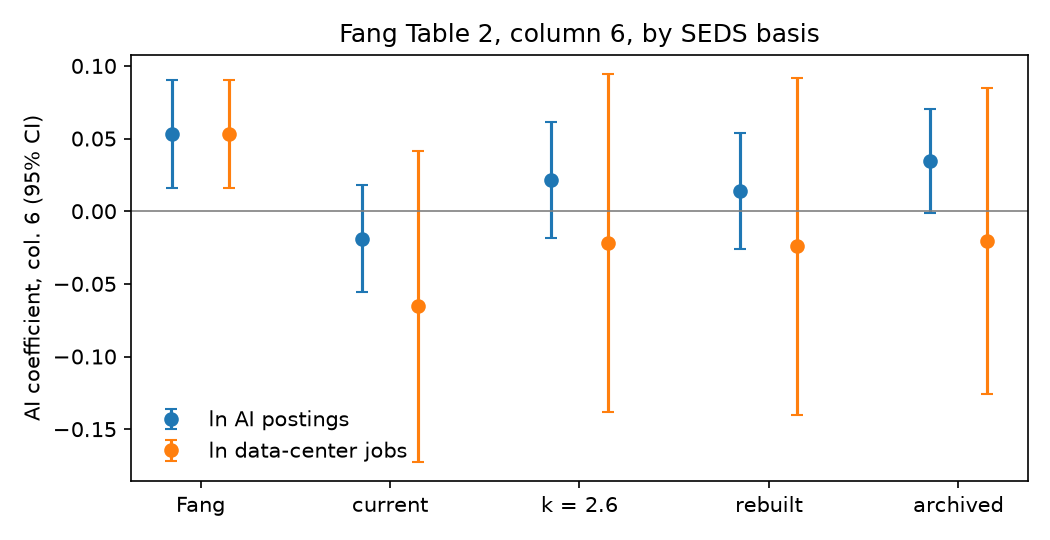

,tag,spec,ai_measure,outcome,estimate,se,pval,ci_lo,ci_hi,N
0,fang8_final_current_aipostings_lag1_state-year_cl-state_lnET_50s20...,current,aipostings,lnET,-0.047862,0.029310,0.108889,-0.106762,0.011039,300
1,fang8_final_current_dcjobs_lag1_state-year_cl-state_lnET_50s2015_2...,current,dcjobs,lnET,-0.056718,0.044416,0.207633,-0.145975,0.032540,500
2,fang8_final_k26_aipostings_lag1_state-year_cl-state_lnET_k26_50s20...,k26,aipostings,lnET_k26,-0.047152,0.030308,0.126205,-0.108059,0.013755,300
3,fang8_final_k26_dcjobs_lag1_state-year_cl-state_lnET_k26_50s2015_2...,k26,dcjobs,lnET_k26,-0.092961,0.056246,0.104774,-0.205991,0.020069,500
4,fang8_final_rebuilt_aipostings_lag1_state-year_cl-state_lnET_rb_50...,rebuilt,aipostings,lnET_rb,-0.047792,0.030815,0.127349,-0.109717,0.014132,300
5,fang8_final_rebuilt_dcjobs_lag1_state-year_cl-state_lnET_rb_50s201...,rebuilt,dcjobs,lnET_rb,-0.096922,0.056964,0.095198,-0.211396,0.017553,500
6,fang8_final_allconv_aipostings_lag1_state-year_cl-state_lnET_ac_50...,allconv,aipostings,lnET_ac,-0.047427,0.030010,0.120455,-0.107735,0.012880,300
7,fang8_final_allconv_dcjobs_lag1_state-year_cl-state_lnET_ac_50s201...,allconv,dcjobs,lnET_ac,-0.094984,0.056643,0.099930,-0.208812,0.018843,500


In [17]:
t2 = pd.read_csv(T8 + 'fang8_table2_by_basis.csv')
display(t2[t2.term == 'AI'][['ai_measure', 'column', 'fang', 'current', 'current_p', 'k26', 'k26_p', 'rebuilt', 'rebuilt_p', 'archived', 'archived_p', 'rebuilt_fang_in_ci', 'archived_fang_in_ci']])
display(t2[(t2.term != 'AI') & (t2.column == 6)][['ai_measure', 'term', 'fang', 'current', 'k26', 'rebuilt', 'archived', 'archived_fang_in_ci']])
display(Image(F8 + 'fig_fang8_table2_by_basis.png', width=750))
display(pd.read_csv(T8 + 'fang8_final_by_basis.csv'))

**Reading:** with postings, Table 2 largely reproduces on SEDS as Fang would have downloaded it: same sign, similar size in columns 1-2, about two-thirds of Fang's size in column 6. Fang's coefficients sit inside our 95% CIs, but Fang's own SEs (0.015-0.019) make that a loose test. The year-by-year rebuild on today's data turns the sign positive but is smaller and mostly not significant, so both the accounting change and later data revisions matter. With data-center jobs, no basis gives a positive association. In our spec, no basis is significant at 5%.

## 9. Splits table (Fang Tables 3-5)

**What Fang did:** separate regressions for states above and below "the mean across the 51 states" in electricity consumption, electricity price, net electricity trade, R&D funding, per capita income and extreme weather, plus the four Census regions (Tables 3-5, PDF pp. 5-6).

**What we ran and why:** for each group, Fang's mean split, a median split (Fang's group sizes look like medians, F14), and the interaction test (the difference with its SE and p), in Fang's spec and in ours. Rows that ran on Nov 4 reproduce exactly (gate). Separate regressions in our spec are new. F27 adds Fang's spec on the archived outcome.

$$\ln ET_{it} = \beta_1 \ln AI_{it} + \delta\,(\ln AI_{it} \times H_i) + \ldots,\quad H_i = 1[\bar{x}_{i,2018\text{-}21} > \text{mean or median}]$$

,group,split,ai_measure,fang_high,fang_low,fangspec_high,fangspec_low,fangspec_diff,ourspec_high,ourspec_low,ourspec_diff,matches_fang_pattern_fangspec,archived_high,archived_low,matches_fang_pattern_archived
0,Electricity consumption,mean,ln AI postings,"-0.0025 (SE 0.026, N 104)","+0.0730 (SE 0.028, N 100)",-0.0388** (p=0.046),-0.0049 (p=0.863),+0.0356 (p=0.232),-0.0274 (p=0.612),-0.0675** (p=0.032),+0.0045 (p=0.828),"same ordering, not significant",-0.0110 (p=0.621),+0.0602** (p=0.024),matches
1,Electricity consumption,median,ln AI postings,"-0.0025 (SE 0.026, N 104)","+0.0730 (SE 0.028, N 100)",-0.0466** (p=0.018),-0.0010 (p=0.975),+0.0204 (p=0.465),-0.0114 (p=0.790),-0.0909** (p=0.014),+0.0033 (p=0.880),"same ordering, not significant",-0.0247 (p=0.228),+0.0681** (p=0.019),matches
2,Electricity consumption,mean,ln data-center jobs,"-0.0025 (SE 0.026, N 104)","+0.0730 (SE 0.028, N 100)",-0.1071 (p=0.148),-0.0545 (p=0.445),+0.1009 (p=0.398),-0.0969 (p=0.163),-0.0484 (p=0.427),-0.0073 (p=0.949),"same ordering, not significant",-0.0635 (p=0.450),-0.0156 (p=0.821),"same ordering, not significant"
3,Electricity consumption,median,ln data-center jobs,"-0.0025 (SE 0.026, N 104)","+0.0730 (SE 0.028, N 100)",-0.0537 (p=0.477),-0.0648 (p=0.398),+0.1057 (p=0.343),-0.0438 (p=0.475),-0.0577 (p=0.346),+0.0082 (p=0.942),does not match,-0.0220 (p=0.777),-0.0259 (p=0.726),does not match
4,Electricity price,mean,ln AI postings,"+0.0628 (SE 0.03, N 108)","+0.0334 (SE 0.026, N 96)",-0.0736 (p=0.114),-0.0013 (p=0.944),-0.0988*** (p=0.003),-0.1070 (p=0.120),-0.0053 (p=0.866),-0.0599** (p=0.040),does not match,+0.0516 (p=0.133),+0.0291 (p=0.164),"same ordering, not significant"
5,Electricity price,median,ln AI postings,"+0.0628 (SE 0.03, N 108)","+0.0334 (SE 0.026, N 96)",-0.0346 (p=0.269),-0.0036 (p=0.872),-0.0221 (p=0.430),-0.0729 (p=0.146),-0.0201 (p=0.599),-0.0238 (p=0.326),does not match,+0.0450* (p=0.084),+0.0314 (p=0.219),matches
6,Electricity price,mean,ln data-center jobs,"+0.0628 (SE 0.03, N 108)","+0.0334 (SE 0.026, N 96)",-0.1786 (p=0.258),-0.0847 (p=0.101),-0.0669 (p=0.585),-0.1576 (p=0.132),-0.0146 (p=0.776),-0.1405 (p=0.190),does not match,+0.1244 (p=0.285),-0.0926 (p=0.116),"same ordering, not significant"
7,Electricity price,median,ln data-center jobs,"+0.0628 (SE 0.03, N 108)","+0.0334 (SE 0.026, N 96)",+0.0223 (p=0.827),-0.1338** (p=0.025),+0.1041 (p=0.302),-0.0622 (p=0.465),-0.0540 (p=0.392),-0.0128 (p=0.895),"same ordering, not significant",+0.2134** (p=0.011),-0.1629** (p=0.018),partly (both sides significant)
8,Net producer (high = producer),binary,ln AI postings,"-0.0060 (SE 0.034, N 76)","+0.0425 (SE 0.024, N 128)",+0.0024 (p=0.908),-0.1401*** (p=0.000),+0.0864*** (p=0.003),-0.0080 (p=0.821),-0.1144* (p=0.060),+0.0641*** (p=0.007),does not match,+0.0517** (p=0.017),-0.0513 (p=0.112),does not match
9,Net producer (high = producer),binary,ln data-center jobs,"-0.0060 (SE 0.034, N 76)","+0.0425 (SE 0.024, N 128)",-0.0707 (p=0.240),-0.1537 (p=0.141),+0.0966 (p=0.367),-0.0768 (p=0.109),-0.1344 (p=0.104),+0.0958 (p=0.430),does not match,-0.0723 (p=0.261),+0.0152 (p=0.859),"same ordering, not significant"


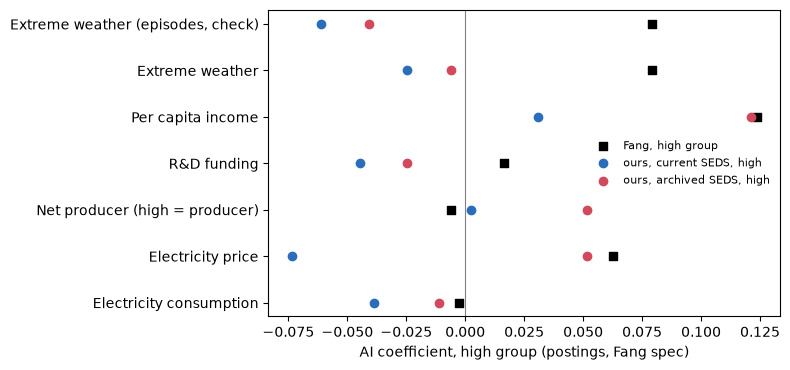

In [18]:
sp = pd.read_csv(T8 + 'fang8_splits_table.csv')
display(sp[['group', 'split', 'ai_measure', 'fang_high', 'fang_low', 'fangspec_high', 'fangspec_low', 'fangspec_diff', 'ourspec_high', 'ourspec_low', 'ourspec_diff', 'matches_fang_pattern_fangspec', 'archived_high', 'archived_low', 'matches_fang_pattern_archived']])
import matplotlib.pyplot as plt, re
x = sp[(sp.ai_measure == 'ln AI postings') & (sp.split.isin(['mean', 'binary']))]
num = lambda s: float(re.match(r'([+-]?[0-9.]+)', s).group(1)) if isinstance(s, str) and s else float('nan')
fig, ax = plt.subplots(figsize=(8, 3.8)); ys = range(len(x))
ax.scatter([num(v) for v in x.fang_high], ys, marker='s', color='k', label='Fang, high group')
ax.scatter([num(v) for v in x.fangspec_high], ys, color='#2a6ebb', label='ours, current SEDS, high')
ax.scatter([num(v) for v in x.archived_high], ys, color='#d1495b', label='ours, archived SEDS, high')
ax.set_yticks(list(ys)); ax.set_yticklabels(x.group); ax.axvline(0, color='grey', lw=.8); ax.set_xlabel('AI coefficient, high group (postings, Fang spec)')
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

**Reading:** on current SEDS, Fang's subgroup pattern doesn't reproduce in Fang's spec, and our interaction tests find almost no group differences. On the archived outcome with postings (F27, added after seeing Table 2, so **exploratory**), part of it does: low-consumption, low-R&D and high-income states and the Midwest match Fang's side. **Fang's headline splits, electricity price and net producer, don't reproduce on either basis**, and neither does extreme weather.

## 10. Negative indicator (Fang Supplement B)

**What Fang did:** checked robustness with negative indicators of energy transition: total coal, natural gas and petroleum consumption (Supplement Table B1, filed Nov 7 as `literature/Fang_Lee_Li_2025_supplement.docx`). Fang reports AI at -0.178 (t -1.43), 0.0023 (t 0.13) and -0.0160 (t -1.08). The by-number comparison is in `notebooks/09_extend.ipynb`, section 1: coal and gas fall inside our CIs, petroleum doesn't.

**What we ran and why:** SEDS fossil-fuel consumption (FFTCB) in logs, and as a share of total energy (FFTCB / TETCB, in levels). If AI goes with a faster transition, the sign should be negative.

$$Y_{it} \in \{\ln FF_{it},\ FF_{it}/TE_{it}\} = \beta_1 \ln AI + \ldots$$

,tag,spec,ai_measure,outcome,estimate,se,pval,ci_lo,ci_hi,N
0,fang8_neg_fang_aipostings_contemp_state_iid_lnFossil_51s2018_2021_AI,fang,aipostings,lnFossil,-0.011093,0.009093,0.224438,-0.029064,0.006877,204
1,fang8_neg_twfe_aipostings_lag1_state-year_cl-state_lnFossil_50s201...,twfe,aipostings,lnFossil,0.029639,0.014177,0.041769,0.001149,0.058129,300
2,fang8_neg_fang_aipostings_contemp_state_iid_fossilShare_51s2018_20...,fang,aipostings,fossilShare,-0.001362,0.004696,0.772181,-0.010643,0.007919,204
3,fang8_neg_twfe_aipostings_lag1_state-year_cl-state_fossilShare_50s...,twfe,aipostings,fossilShare,0.013597,0.009475,0.157618,-0.005443,0.032638,300
4,fang8_neg_fang_dcjobs_contemp_state_iid_lnFossil_51s2018_2021_AI,fang,dcjobs,lnFossil,0.011463,0.026484,0.665769,-0.040876,0.063803,204
5,fang8_neg_twfe_dcjobs_lag1_state-year_cl-state_lnFossil_50s2015_20...,twfe,dcjobs,lnFossil,0.026075,0.023466,0.271927,-0.021083,0.073232,500
6,fang8_neg_fang_dcjobs_contemp_state_iid_fossilShare_51s2018_2021_AI,fang,dcjobs,fossilShare,0.004467,0.013617,0.743359,-0.022444,0.031377,204
7,fang8_neg_twfe_dcjobs_lag1_state-year_cl-state_fossilShare_50s2015...,twfe,dcjobs,fossilShare,0.017155,0.018718,0.363918,-0.020462,0.054771,500


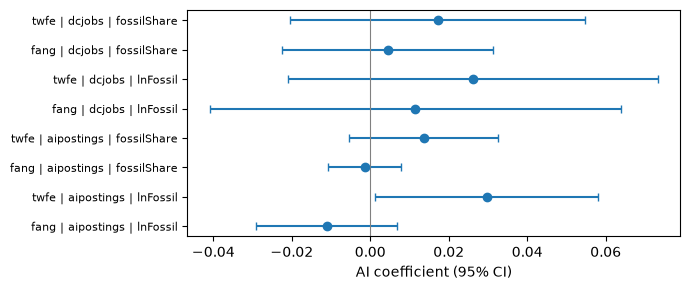

In [19]:
display(pd.read_csv(T8 + 'fang8_negative_indicator.csv'))
ng = pd.read_csv(T8 + 'fang8_negative_indicator.csv')
fig, ax = plt.subplots(figsize=(7, 3)); lab = ng.spec + ' | ' + ng.ai_measure + ' | ' + ng.outcome
ax.errorbar(ng.estimate, range(len(ng)), xerr=[ng.estimate - ng.ci_lo, ng.ci_hi - ng.estimate], fmt='o', capsize=3)
ax.set_yticks(range(len(ng))); ax.set_yticklabels(lab, fontsize=8); ax.axvline(0, color='grey', lw=.8); ax.set_xlabel('AI coefficient (95% CI)'); fig.tight_layout(); plt.show()

**Reading:** none of the eight estimates is negative and significant. The only significant one, postings with ln fossil fuel in our spec (+0.0296, p = 0.042), goes the other way. So the negative indicator doesn't support Fang's story.

## 11. Extreme-weather split (Fang Table 4, columns 5-6)

**What Fang did:** split states by "the number of extreme hot and cold weather occurrences within a year," above vs below the 51-state mean (PDF p. 5): AI is +0.0790 (p < 0.05) in high-frequency states and +0.0145 (not significant) in low.

**What we ran and why:** NOAA Storm Events records of Excessive Heat, Heat, Extreme Cold/Wind Chill and Cold/Wind Chill, counted per state-year (receipt `noaa_storm_events.md`). Each state's 2018-2021 average is split at the mean (19 states, 76 state-years, against Fang's 104) and at the median. Distinct episodes are a check. Reporting differs by NWS office, so the counts are rated yellow.

,group,split,ai_measure,fang_high,fang_low,fangspec_high,N_high,fangspec_low,N_low,fangspec_diff,ourspec_diff,archived_high,archived_low
18,Extreme weather,mean,ln AI postings,"+0.0790 (SE 0.03, N 104)","+0.0145 (SE 0.026, N 100)",-0.0245 (p=0.262),76,-0.0215 (p=0.434),128.0,+0.0360 (p=0.206),+0.0156 (p=0.494),-0.0060 (p=0.782),+0.0522** (p=0.043)
19,Extreme weather,median,ln AI postings,"+0.0790 (SE 0.03, N 104)","+0.0145 (SE 0.026, N 100)",-0.0120 (p=0.584),100,-0.0365 (p=0.247),104.0,+0.0517* (p=0.055),+0.0423* (p=0.089),+0.0221 (p=0.368),+0.0338 (p=0.215)
20,Extreme weather,mean,ln data-center jobs,"+0.0790 (SE 0.03, N 104)","+0.0145 (SE 0.026, N 100)",-0.1106* (p=0.082),76,-0.0854 (p=0.286),128.0,+0.0552 (p=0.571),+0.1296 (p=0.231),-0.0659 (p=0.297),-0.0294 (p=0.698)
21,Extreme weather,median,ln data-center jobs,"+0.0790 (SE 0.03, N 104)","+0.0145 (SE 0.026, N 100)",-0.0869 (p=0.144),100,-0.0450 (p=0.653),104.0,+0.0245 (p=0.804),+0.1728* (p=0.086),-0.1010 (p=0.129),+0.0957 (p=0.266)
22,"Extreme weather (episodes, check)",mean,ln AI postings,+0.0790,+0.0145,-0.0613** (p=0.045),72,-0.0032 (p=0.896),132.0,+0.0173 (p=0.561),+0.0266 (p=0.249),-0.0407 (p=0.169),+0.0543** (p=0.020)
23,"Extreme weather (episodes, check)",mean,ln data-center jobs,+0.0790,+0.0145,-0.0860 (p=0.241),72,-0.0944 (p=0.220),132.0,+0.0942 (p=0.334),+0.1928 (p=0.115),-0.0425 (p=0.548),-0.0357 (p=0.632)


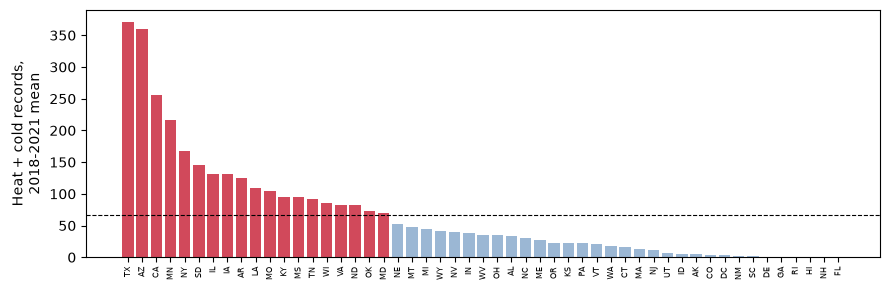

In [20]:
display(sp[sp.group.str.startswith('Extreme weather')][['group', 'split', 'ai_measure', 'fang_high', 'fang_low', 'fangspec_high', 'N_high', 'fangspec_low', 'N_low', 'fangspec_diff', 'ourspec_diff', 'archived_high', 'archived_low']])
ew = pd.read_csv('../results/2026-11-07/fang/split_groups_08.csv').sort_values('ew_count', ascending=False)
fig, ax = plt.subplots(figsize=(9, 3)); ax.bar(ew.state, ew.ew_count, color=['#d1495b' if h else '#9bb7d4' for h in ew.h_w_mean])
ax.axhline(ew.ew_count.mean(), color='k', lw=.8, ls='--'); ax.set_ylabel('Heat + cold records,\n2018-2021 mean'); ax.tick_params(axis='x', labelsize=6, rotation=90); fig.tight_layout(); plt.show()

**Reading:** Fang's weather pattern doesn't reproduce: in Fang's spec, both groups are negative and not significant on current SEDS, and on the archived outcome only the low-frequency group is positive (+0.0522, p = 0.043), the opposite of Fang. Our interaction tests are borderline at most (p = 0.086-0.089 for median splits).

## 12. Event study (optional item 5)

**What we ran and why:** exposure is each state's 2019 share of U.S. AI postings, from one edition (2022). The model asks whether high-exposure states' renewables pulled away after 2021.

$$\ln ET_{it} = \sum_{k \ne 2021} \beta_k\,(E_i \times 1[t = k]) + \text{ctrl4}_{it} + \alpha_i + \gamma_t + \varepsilon_{it}$$

50 states without DC, 2015-2024, clustered by state. Each $\beta_k$ is per 1 percentage point of 2019 postings share.

,spec,term,estimate,se,pval,note
0,current,b2015,-0.011284,0.007773,0.152971,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
1,current,b2016,-0.008882,0.006247,0.161382,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
2,current,b2017,-0.006183,0.005548,0.270531,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
3,current,b2018,-0.009192,0.004647,0.053564,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
4,current,b2019,-0.005755,0.004297,0.186694,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
5,current,b2020,-0.001733,0.002084,0.409682,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
6,current,b2022,0.004552,0.001746,0.012042,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
7,current,b2023,0.013650,0.003356,0.000172,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
8,current,b2024,0.017944,0.004618,0.000306,per 1 pp of 2019 U.S. postings share (2022 edition); base 2021; ctrl4
9,current,joint_pre_2015_2020,3.012684,NaN,0.013809,"Wald F, df1 = 6"


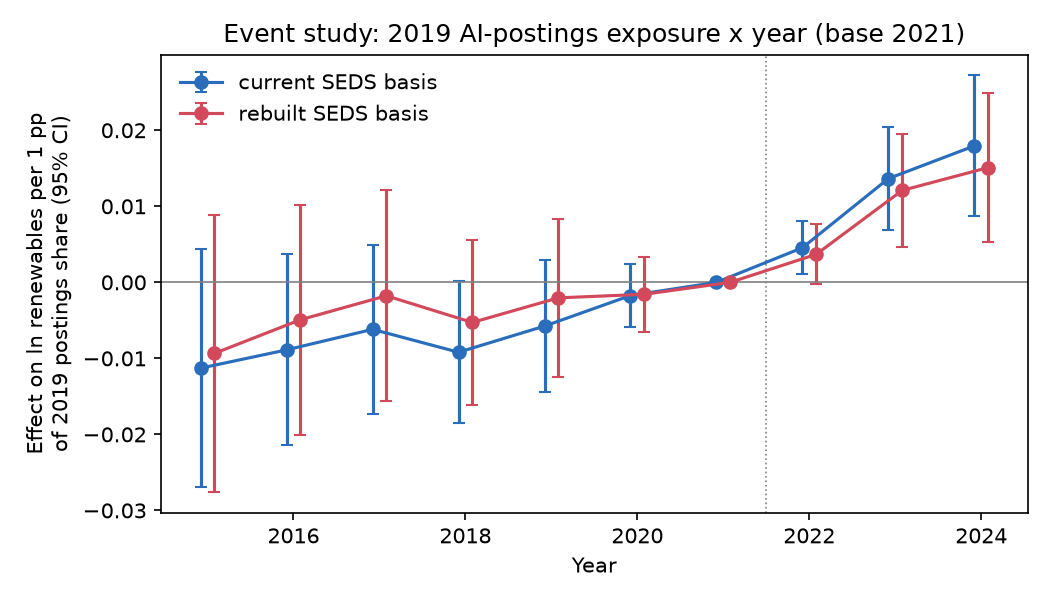

In [21]:
es = pd.read_csv(T8 + 'fang8_event_study.csv'); display(es[['spec', 'term', 'estimate', 'se', 'pval', 'note']])
display(Image(F8 + 'fig_fang8_event_study.png', width=700))

**Reading:** after 2021, states with a larger 2019 share of AI postings are associated with faster renewable growth (joint p = 0.001 current, 0.006 rebuilt). But the pre-2021 coefficients rise steadily toward zero, and on current SEDS they're jointly significant (p = 0.014), so the post-2021 gap looks like a trend that was already under way, not a break.